# 02 · Cluster Report — K-Means & Hierarchical Clustering
Segment employees, validate the clusters, and analyse risk, department, performance and retention.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
df = pd.read_csv("../data/employees.csv")
FEATURES = [c for c in df.columns if c not in ("employee_id", "department", "left_company")]
X = StandardScaler().fit_transform(df[FEATURES])
pca = PCA(n_components=0.85, random_state=42); Z = pca.fit_transform(X)
print("PCA input to clustering:", Z.shape)

PCA input to clustering: (1200, 7)


## 1. K-Means — choosing K (elbow + silhouette)

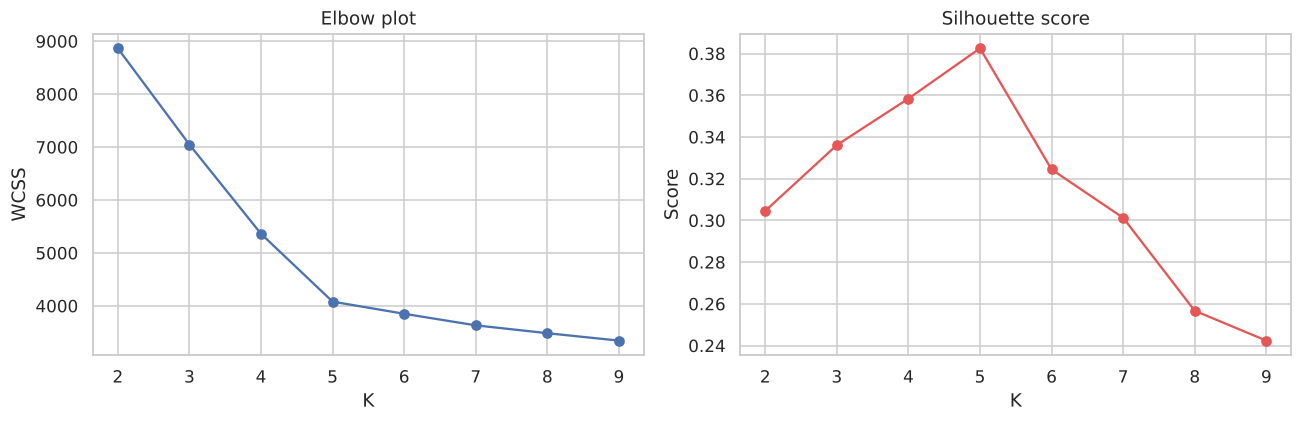

 K   WCSS  Silhouette
 2 8865.0       0.305
 3 7047.0       0.336
 4 5361.0       0.358
 5 4079.0       0.383
 6 3850.0       0.324
 7 3632.0       0.301
 8 3483.0       0.257
 9 3343.0       0.242
Chosen K = 5


In [2]:
ks = range(2, 10); wcss, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(Z); wcss.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, wcss, "o-"); ax[0].set(title="Elbow plot", xlabel="K", ylabel="WCSS")
ax[1].plot(ks, sil, "o-", color="#E45756"); ax[1].set(title="Silhouette score", xlabel="K", ylabel="Score")
plt.tight_layout(); plt.savefig("../reports/fig_elbow_silhouette.png", bbox_inches="tight"); plt.show()
print(pd.DataFrame({"K": list(ks), "WCSS": np.round(wcss), "Silhouette": np.round(sil, 3)}).to_string(index=False))
K = int(list(ks)[int(np.argmax(sil))]); print("Chosen K =", K)

The silhouette score peaks at **K = 5** and the elbow flattens after 5, so we use five segments.

In [3]:
km = KMeans(K, n_init=10, random_state=42).fit(Z)
df["kmeans_cluster"] = km.labels_
print("Silhouette (K-Means):", round(silhouette_score(Z, km.labels_), 3))

Silhouette (K-Means): 0.383


## 2. Hierarchical clustering (Ward linkage)

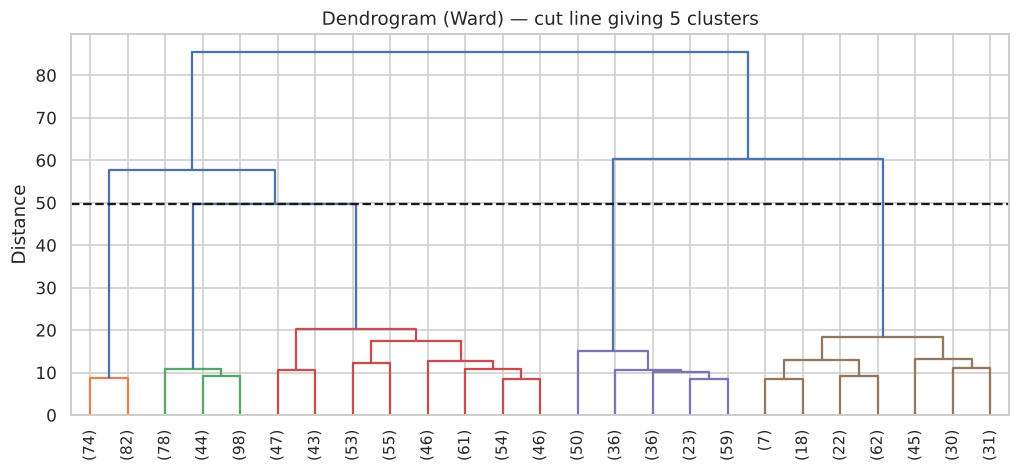

Silhouette (Hierarchical): 0.373
Agreement with K-Means (Adjusted Rand Index): 0.903


In [4]:
L = linkage(Z, method="ward")
plt.figure(figsize=(11, 4.5))
dendrogram(L, truncate_mode="lastp", p=25, leaf_rotation=90, color_threshold=L[-(K-1), 2])
plt.axhline(L[-(K-1), 2], ls="--", color="k"); plt.title("Dendrogram (Ward) — cut line giving 5 clusters"); plt.ylabel("Distance")
plt.savefig("../reports/fig_dendrogram.png", bbox_inches="tight"); plt.show()
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
df["hier_cluster"] = hc.labels_
print("Silhouette (Hierarchical):", round(silhouette_score(Z, hc.labels_), 3))
print("Agreement with K-Means (Adjusted Rand Index):", round(adjusted_rand_score(km.labels_, hc.labels_), 3))

Both algorithms recover nearly the same structure (high ARI), which is strong evidence the segments are real. We carry **K-Means** forward for profiling.

## 3. Profiling and naming the segments
Cluster IDs are arbitrary, so segments are named from their *profiles* with transparent rules.

In [5]:
prof = df.groupby("kmeans_cluster")[FEATURES + ["left_company"]].mean()
names = {}
names[prof.overtime_hours_month.idxmax()] = "Burnout Risk"
rest = prof.drop(index=list(names))
names[rest.performance_rating.idxmin()] = "Disengaged Low Performers"
rest = prof.drop(index=list(names))
names[rest.performance_rating.idxmax()] = "High Performers"
rest = prof.drop(index=list(names))
names[rest.tenure_years.idxmin()] = "New Joiners"
names[[i for i in prof.index if i not in names][0]] = "Steady Core"
df["segment"] = df.kmeans_cluster.map(names)
order = ["High Performers", "Steady Core", "New Joiners", "Burnout Risk", "Disengaged Low Performers"]
seg = df.groupby("segment").agg(headcount=("employee_id", "count"), **{f: (f, "mean") for f in FEATURES}, attrition_rate=("left_company", "mean")).loc[order]
seg["share_%"] = (seg.headcount / len(df) * 100).round(1)
seg.round(2).T

segment,High Performers,Steady Core,New Joiners,Burnout Risk,Disengaged Low Performers
headcount,235.00,369.00,178.00,205.00,213.00
age,36.56,42.54,26.15,34.01,39.97
tenure_years,6.98,10.51,1.20,4.82,6.89
monthly_salary,8029.06,5882.71,3761.69,5155.56,4164.32
performance_rating,4.49,3.50,3.10,3.88,2.42
engagement_score,8.15,7.13,6.86,4.42,3.06
overtime_hours_month,18.41,8.21,9.26,41.96,6.34
absenteeism_days,2.14,4.03,3.28,9.82,11.18
training_hours,48.26,25.34,38.11,14.71,7.73
years_since_promotion,1.57,3.49,0.63,3.20,4.13


## 4. PCA visual validation

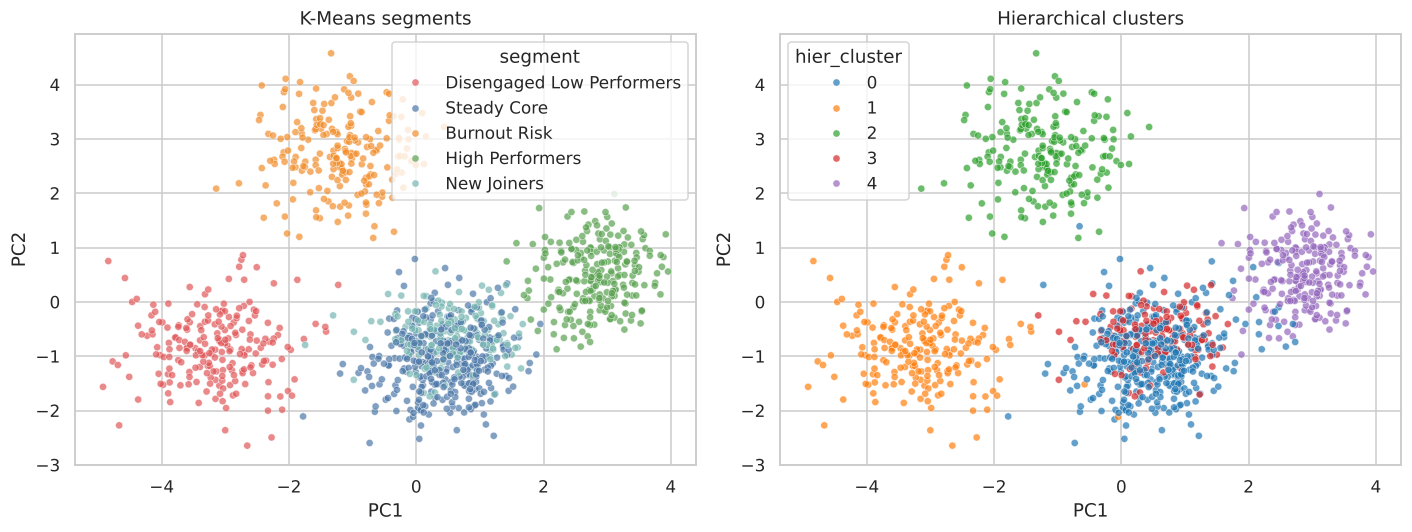

In [6]:
palette = dict(zip(order, ["#59A14F", "#4C78A8", "#76B7B2", "#F28E2B", "#E15759"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, col, t in [(ax[0], "segment", "K-Means segments"), (ax[1], "hier_cluster", "Hierarchical clusters")]:
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df[col], palette=palette if col == "segment" else "tab10", s=22, alpha=.7, ax=a)
    a.set(title=t, xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.savefig("../reports/fig_clusters_pca.png", bbox_inches="tight"); plt.show()

## 5. High-risk employee clusters — Risk Matrix
Risk is defined from workforce signals (not from the attrition label): **burnout exposure** (overtime, absenteeism) vs **disengagement** (low engagement, low manager rating).

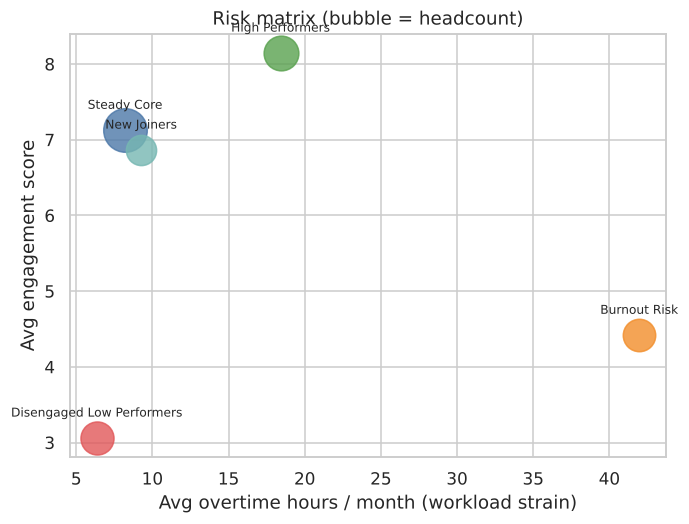

High-risk employees (top 15% score): 180
segment
High Performers              0.000
Steady Core                  0.000
New Joiners                  0.000
Burnout Risk                 0.571
Disengaged Low Performers    0.296
Name: high_risk_flag, dtype: float64


,burnout,absence,engagement,risk_score,attrition
segment,,,,,
High Performers,18.41,2.14,8.15,-0.64,0.13
Steady Core,8.21,4.03,7.13,-0.45,0.15
New Joiners,9.26,3.28,6.86,-0.42,0.16
Burnout Risk,41.96,9.82,4.42,1.08,0.83
Disengaged Low Performers,6.34,11.18,3.06,0.80,0.70


In [7]:
def z(s): return (s - s.mean()) / s.std()
df["risk_score"] = (z(df.overtime_hours_month) + z(df.absenteeism_days) - z(df.engagement_score) - z(df.manager_rating)) / 4
rm = df.groupby("segment").agg(burnout=("overtime_hours_month", "mean"), absence=("absenteeism_days", "mean"),
        engagement=("engagement_score", "mean"), risk_score=("risk_score", "mean"), attrition=("left_company", "mean")).loc[order]
plt.figure(figsize=(7, 5))
for s, r in rm.iterrows():
    plt.scatter(r.burnout, r.engagement, s=seg.loc[s, "headcount"]*2.2, color=palette[s], alpha=.8); plt.annotate(s, (r.burnout, r.engagement), ha="center", fontsize=8, xytext=(0, 14), textcoords="offset points")
plt.xlabel("Avg overtime hours / month (workload strain)"); plt.ylabel("Avg engagement score"); plt.title("Risk matrix (bubble = headcount)")
plt.savefig("../reports/fig_risk_matrix.png", bbox_inches="tight"); plt.show()
cut = df.risk_score.quantile(.85); df["high_risk_flag"] = (df.risk_score >= cut).astype(int)
print("High-risk employees (top 15% score):", df.high_risk_flag.sum())
print(df.groupby("segment").high_risk_flag.mean().loc[order].round(3))
rm.round(2)

## 6. Department-level workforce segments

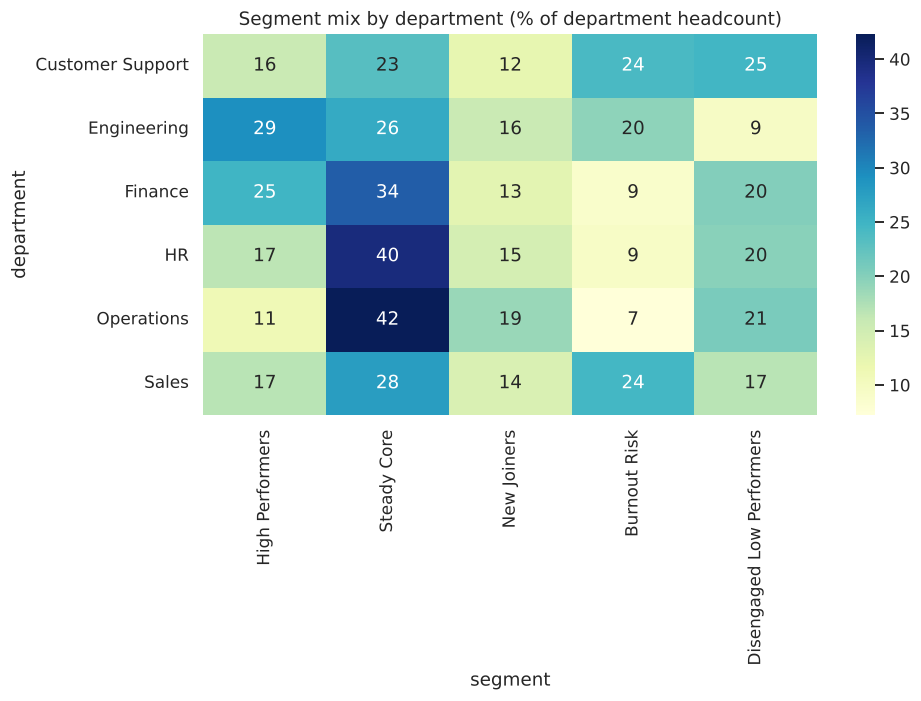

,headcount,avg_perf,avg_engagement,avg_overtime,attrition,high_risk_share
department,,,,,,
Customer Support,211,3.45,5.64,17.45,0.45,0.23
Sales,249,3.51,5.90,17.86,0.46,0.18
Engineering,287,3.68,6.48,17.80,0.33,0.13
Operations,208,3.32,6.13,12.03,0.29,0.12
HR,96,3.49,6.12,12.17,0.30,0.11
Finance,149,3.54,6.31,13.72,0.26,0.09


In [8]:
ct = pd.crosstab(df.department, df.segment, normalize="index").loc[:, order] * 100
plt.figure(figsize=(9, 4.5)); sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlGnBu"); plt.title("Segment mix by department (% of department headcount)")
plt.savefig("../reports/fig_dept_segments.png", bbox_inches="tight"); plt.show()
dept = df.groupby("department").agg(headcount=("employee_id", "count"), avg_perf=("performance_rating", "mean"), avg_engagement=("engagement_score", "mean"),
        avg_overtime=("overtime_hours_month", "mean"), attrition=("left_company", "mean"), high_risk_share=("high_risk_flag", "mean")).round(2)
dept.sort_values("high_risk_share", ascending=False)

## 7. Performance groups

In [9]:
df["performance_group"] = pd.cut(df.performance_rating, [0, 2.9, 3.9, 5], labels=["Low (<3)", "Solid (3–3.9)", "Top (≥4)"])
pg = pd.crosstab(df.segment, df.performance_group, normalize="index").loc[order] * 100
pg.round(1)

performance_group,Low (<3),Solid (3–3.9),Top (≥4)
segment,,,
High Performers,0.0,4.7,95.3
Steady Core,7.6,79.7,12.7
New Joiners,37.1,58.4,4.5
Burnout Risk,4.4,48.8,46.8
Disengaged Low Performers,85.4,14.6,0.0


## 8. Retention risk groups
Historical attrition is used here **only to validate** the unsupervised segments.

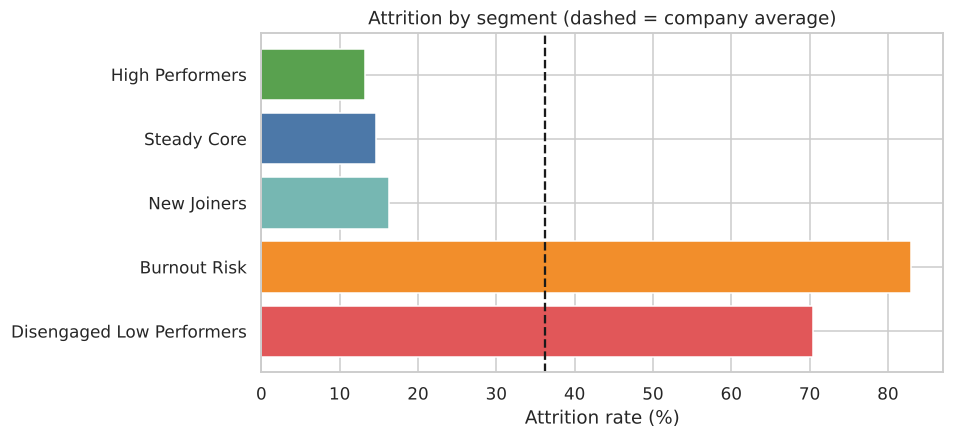

retention_risk
Low       782
High      418
Medium      0
Name: count, dtype: int64


,attrition_rate,leavers,headcount
segment,,,
High Performers,0.132,31,235
Steady Core,0.146,54,369
New Joiners,0.163,29,178
Burnout Risk,0.829,170,205
Disengaged Low Performers,0.704,150,213


In [10]:
ret = df.groupby("segment").left_company.agg(["mean", "sum", "count"]).loc[order]; ret.columns = ["attrition_rate", "leavers", "headcount"]
fig, ax = plt.subplots(figsize=(8, 4)); ax.barh(ret.index[::-1], ret.attrition_rate[::-1] * 100, color=[palette[s] for s in ret.index[::-1]])
ax.axvline(df.left_company.mean() * 100, ls="--", color="k"); ax.set(xlabel="Attrition rate (%)", title="Attrition by segment (dashed = company average)")
plt.savefig("../reports/fig_retention.png", bbox_inches="tight"); plt.show()
df["retention_risk"] = pd.cut(df.segment.map(ret.attrition_rate), [0, .25, .5, 1], labels=["Low", "Medium", "High"])
print(df.retention_risk.value_counts())
ret.round(3)

## 9. Save outputs for the dashboard

In [11]:
pcs = pd.DataFrame(Z[:, :3], columns=["PC1", "PC2", "PC3"])
out = pd.concat([df, pcs], axis=1)
out.to_csv("../data/employees_segmented.csv", index=False)
seg.round(3).to_csv("../reports/segment_profiles.csv"); dept.to_csv("../reports/department_summary.csv"); ret.round(3).to_csv("../reports/retention_by_segment.csv")
print("Saved", out.shape)

Saved (1200, 25)
